<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2027%3A%20Deep%20Belief%20Network%20Representation%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

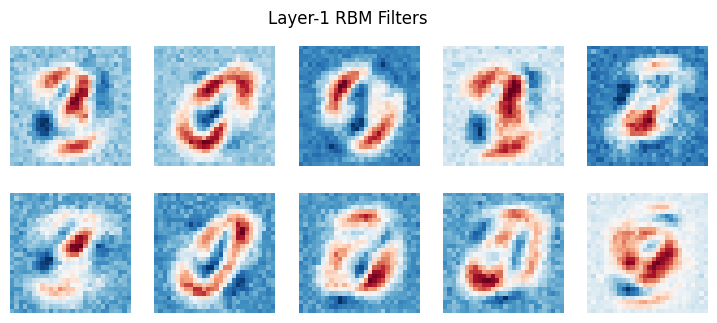

DBN Accuracy: 0.7740 | Random Init Accuracy: 0.8520


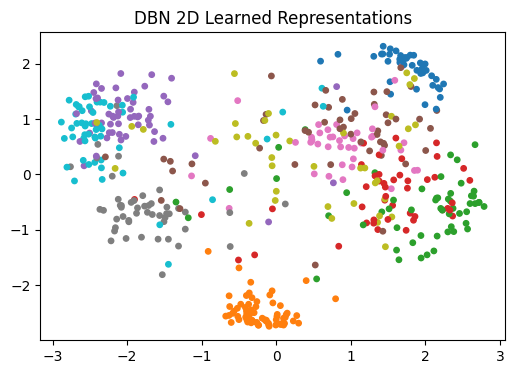

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

(X_tr, y_tr), (X_te, y_te) = keras.datasets.mnist.load_data()
X_u = (X_tr[:2000].reshape(-1, 784) > 127).astype(np.float32)
X_l, y_l = X_u[:1000], y_tr[:1000]
X_test, y_test = (X_te[:500].reshape(-1, 784) > 127).astype(np.float32), y_te[:500]
sig = lambda x: 1.0 / (1.0 + np.exp(-np.clip(x, -20, 20)))

def pretrain(d, nv, nh):
    W = np.random.normal(0, 0.01, (nv, nh)).astype(np.float32)
    a, b = np.zeros(nv, dtype=np.float32), np.zeros(nh, dtype=np.float32)
    for _ in range(4):
        for i in range(0, len(d), 50):
            v0 = d[i:i+50]
            ph0 = sig(v0 @ W + b)
            pv1 = sig((np.random.rand(*ph0.shape) < ph0) @ W.T + a)
            ph1 = sig(pv1 @ W + b)
            W += 0.05 * ((v0.T @ ph0) - (pv1.T @ ph1)) / len(v0)
            a += 0.05 * np.mean(v0 - pv1, axis=0)
            b += 0.05 * np.mean(ph0 - ph1, axis=0)
    return W, b, sig(d @ W + b)

W1, b1, H1 = pretrain(X_u, 784, 128)
W2, b2, _ = pretrain(H1, 128, 64)

fig, axes = plt.subplots(2, 5, figsize=(9, 3.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(W1[:, i].reshape(28, 28), cmap='RdBu_r'); ax.axis('off')
plt.suptitle("Layer-1 RBM Filters")
plt.show()

def make_net(pre=False):
    # We define input explicitly as a layer in Sequential to keep standard Keras 3 practices
    m = keras.Sequential([
        keras.layers.Input(shape=(784,), name='input_layer'),
        keras.layers.Dense(128, activation='sigmoid', name='l1'),
        keras.layers.Dense(64, activation='sigmoid', name='l2'),
        keras.layers.Dense(10, activation='softmax')
    ])
    if pre:
        m.get_layer('l1').set_weights([W1, b1])
        m.get_layer('l2').set_weights([W2, b2])
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit(X_l, y_l, epochs=10, batch_size=32, verbose=0)
    return m

dbn = make_net(True)
rnd = make_net(False)
print(f"DBN Accuracy: {dbn.evaluate(X_test, y_test, verbose=0)[1]:.4f} | Random Init Accuracy: {rnd.evaluate(X_test, y_test, verbose=0)[1]:.4f}")

# Create a Functional Model for feature extraction using the trained layers
feat_extractor = keras.Model(inputs=dbn.inputs, outputs=dbn.get_layer('l2').output)
feats = PCA(2).fit_transform(feat_extractor.predict(X_test, verbose=0))

plt.figure(figsize=(6, 4))
plt.scatter(feats[:, 0], feats[:, 1], c=y_test, cmap='tab10', s=15)
plt.title("DBN 2D Learned Representations")
plt.show()